# 06 · 平替评分（Alternative Score）

**目标**：把阶段 4（踢法像不像）和阶段 5（是不是便宜）结合成**一个分数**，给出最终的平替排名。

🍜 **比喻**：选“猪肠粉平替店”，请三位评审打分：

| 评审 | 看什么 | 来源 |
|---|---|---|
| 🎨 口味评审 | **风格**像不像（酱料比例） | 阶段 4 Cosine Similarity |
| 💪 份量评审 | **份量**够不够（Cosine 不看份量的补丁） | 本阶段新算的“实力分” |
| 💰 价钱评审 | **划不划算** | 阶段 5 value_ratio |

最后按权重加起来：

$$\text{平替分} = 100 \times (0.5 \times \text{风格} + 0.3 \times \text{实力} + 0.2 \times \text{性价比})$$

核心代码在 `src/scouting.py`，App 会直接使用。

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.scouting import Scout, LEVEL_METRICS, DEFAULT_WEIGHTS

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "font.size": 10,
})

df = pd.read_csv(ROOT / "data" / "processed" / "players_valued.csv")
scout = Scout(df)
print("球员：", len(scout.df), "  默认权重：", DEFAULT_WEIGHTS)

球员： 1410   默认权重： {'style': 0.5, 'level': 0.3, 'value': 0.2}


## 1️⃣ 三个分数怎么算？

| 分数 | 计算方法 | 0 分 | 100 分 |
|---|---|---|---|
| 🎨 **风格** | Cosine 相似度 | 风格无关或相反 | 风格完全一样 |
| 💪 **实力** | 候选人实力分 ÷ 目标实力分（最多算 100%） | — | 达到或超过目标 |
| 💰 **性价比** | 把 value_ratio 换算：0.5× → 0、1× → 33、2× → 67、4× 以上 → 100 | 被高估一半 | 被低估 4 倍 |

**实力分（level，0-100）**：每个角色挑几个“**越高越好**”的指标，算出在**同角色**里的百分位，再取平均。
例如中锋的实力分 90 = 他的产出比 90% 的中锋高。

In [2]:
for role, cols in LEVEL_METRICS.items():
    print(f"{role}: {cols}")

display(scout.df.nlargest(8, "level")[["player", "squad", "role", "level"]])

ST: ['npxg_p90', 'xa_p90', 'xg_chain_p90']
W: ['npxg_p90', 'xa_p90', 'xg_chain_p90']
AM: ['npxg_p90', 'xa_p90', 'xg_chain_p90']
CM: ['xg_chain_p90', 'xg_buildup_p90', 'int_p90', 'tklw_p90']
CB: ['int_p90', 'tklw_p90', 'xg_buildup_p90']
FB: ['int_p90', 'tklw_p90', 'xa_p90', 'xg_buildup_p90']


,player,squad,role,level
197,Harry Kane,Bayern Munich,ST,98.8
288,Raphinha,Barcelona,W,98.8
405,Luis Díaz,Bayern Munich,W,98.3
1079,Michael Olise,Bayern Munich,W,97.9
722,Lamine Yamal,Barcelona,W,97.8
1060,Fermin López,Barcelona,AM,96.3
1361,Lautaro Martínez,Inter,ST,96.0
1206,Deniz Undav,Stuttgart,ST,95.5


💡 **为什么用 log 换算性价比？** 和阶段 3 的身价一样：“便宜一倍”和“贵一倍”应该是**对称**的。
用 `log2`，2 倍 = +1、0.5 倍 = -1，刚好对称。

另外还有**硬性条件**（不符合就直接排除，不参加评分）：

| 条件 | 默认值 | 原因 |
|---|---|---|
| 同角色 | ✅ | 阶段 4 的改进 |
| 比目标便宜 | ✅ | “平替”的定义 |
| 实力 ≥ 目标的 80% | 0.8 | Haaland 平替不能只是“风格像但产出差很多”的人 |

## 2️⃣ 案例：找平替

In [3]:
for name in ["Erling Haaland", "Pedri", "Bukayo Saka"]:
    target, res = scout.find_alternatives(name, n=6)
    print(f"\n🎯 {name}（{target['squad']}，{target['value_end']:.0f}M，实力分 {target['level']:.0f}）")
    display(res[["player", "squad", "age", "value_end", "value_ratio", "level",
                 "score_style", "score_level", "score_value", "alt_score"]])


🎯 Erling Haaland（Manchester City，200M，实力分 90）


,player,squad,age,value_end,value_ratio,level,score_style,score_level,score_value,alt_score
784,Michael Gregoritsch,Augsburg,32.2,1.5,4.00,76.2,82.0,84.0,100.0,86.1
1206,Deniz Undav,Stuttgart,29.9,22.0,3.09,95.5,71.0,100.0,88.0,83.0
21,Rômulo,RB Leipzig,24.4,30.0,1.43,84.7,88.0,94.0,51.0,82.5
519,Patrik Schick,Leverkusen,30.4,18.0,0.99,84.5,96.0,93.0,33.0,82.5
35,Odsonne Édouard,Lens,28.5,12.0,2.28,73.7,86.0,81.0,73.0,82.0
799,Wesley Saïd,Lens,31.2,5.0,2.54,89.7,71.0,99.0,78.0,80.8



🎯 Pedri（Barcelona，150M，实力分 84）


,player,squad,age,value_end,value_ratio,level,score_style,score_level,score_value,alt_score
159,Frenkie de Jong,Barcelona,29.1,35.0,1.46,74.0,97.0,88.0,52.0,85.3
43,Tom Bischof,Bayern Munich,21.0,40.0,0.99,79.6,96.0,95.0,33.0,83.0
552,Rodri,Manchester City,30.0,50.0,0.72,75.0,91.0,89.0,18.0,75.7
277,Nabil Bentaleb,Lille,31.6,4.5,1.67,69.3,79.0,82.0,58.0,75.6
1126,Leon Goretzka,Bayern Munich,31.4,12.0,1.04,74.5,78.0,89.0,35.0,72.7
464,Koke,Atlético Madrid,34.5,5.0,0.66,70.0,89.0,83.0,13.0,72.2



🎯 Bukayo Saka（Arsenal，110M，实力分 86）


,player,squad,age,value_end,value_ratio,level,score_style,score_level,score_value,alt_score
481,Nicolas Pépé,Villarreal,31.1,6.0,2.02,84.5,89.0,99.0,67.0,87.7
240,Florian Thauvin,Lens,33.4,5.0,1.58,91.6,81.0,100.0,55.0,81.7
667,Alejandro Garnacho,Chelsea,22.0,28.0,2.39,84.2,70.0,98.0,75.0,79.3
786,Sheraldo Becker,Mainz 05,31.4,1.5,3.47,90.6,60.0,100.0,93.0,78.7
69,Chris Führich,Stuttgart,28.5,12.0,2.52,83.2,62.0,97.0,78.0,75.7
1179,Kenan Yıldız,Juventus,21.2,75.0,0.99,76.2,85.0,89.0,33.0,75.6


## 3️⃣ 分数拆解：为什么他排第一？

平替分是**三部分加起来**的。把每部分的贡献画出来，就能解释“**为什么推荐他**”。
这叫 **explainability（可解释性）**，App 里也会显示，让使用者**信任**推荐结果。

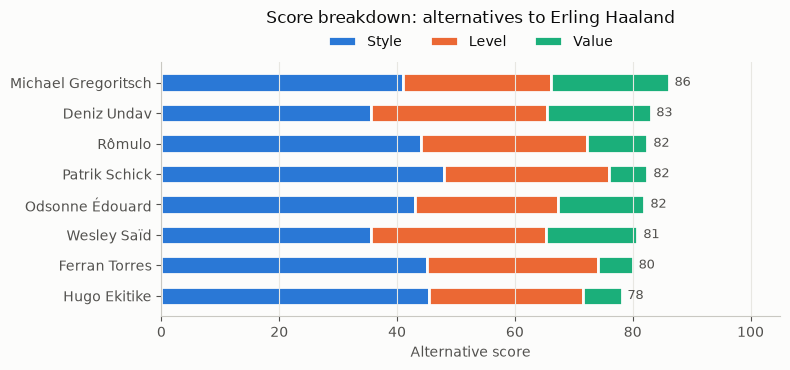

In [4]:
def breakdown(name, **kw):
    target, res = scout.find_alternatives(name, n=8, **kw)
    w = DEFAULT_WEIGHTS
    parts = {
        "Style":  res["score_style"] * w["style"],
        "Level":  res["score_level"] * w["level"],
        "Value":  res["score_value"] * w["value"],
    }
    colors = {"Style": "#2a78d6", "Level": "#eb6834", "Value": "#1baf7a"}
    fig, ax = plt.subplots(figsize=(8, 3.8))
    left = np.zeros(len(res))
    labels = res["player"].values[::-1]
    for k, v in parts.items():
        vals = v.values[::-1]
        ax.barh(labels, vals, left=left, color=colors[k], label=k, height=0.6, edgecolor="#fcfcfb", linewidth=2)
        left += vals
    for y, total in enumerate(res["alt_score"].values[::-1]):
        ax.text(total + 1, y, f"{total:.0f}", va="center", fontsize=9, color="#52514e")
    ax.set(xlim=(0, 105), xlabel="Alternative score")
    ax.set_title(f"Score breakdown: alternatives to {name}", pad=28)
    ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

breakdown("Erling Haaland")

## 4️⃣ 加上 App 的筛选条件

情境：一支球队要找 **Pedri 的平替**，预算 **20M**，要 **26 岁以下**（有转售价值）。

In [5]:
target, res = scout.find_alternatives("Pedri", n=6, max_value=20, age_range=(18, 26))
display(res[["player", "squad", "age", "value_end", "value_ratio", "level", "alt_score"]])

,player,squad,age,value_end,value_ratio,level,alt_score
1111,Miguel Román,Celta Vigo,23.5,15.0,0.79,67.8,67.1
328,Chema,Stuttgart,21.2,20.0,1.46,82.5,60.9
880,Tom Krauß,Köln,25.0,4.5,2.18,71.9,49.0
1188,Mamadou Coulibaly,Monaco,22.2,15.0,1.45,78.2,40.9
171,Luca Lipani,Sassuolo,21.1,7.5,1.63,70.6,36.6
1128,Rocco Reitz,Gladbach,24.1,20.0,0.72,73.5,34.9


🤔 注意 `alt_score` 比上面低很多：预算和年龄限制**排除了最像的人**，剩下的人风格没那么像。
这是**真实的取舍**：预算越紧，越难找到完美平替。App 应该把分数显示出来，让使用者知道“这个平替有多接近”。

## 5️⃣ 权重会怎么影响结果？（Sensitivity Analysis）

权重是**我们自己定的**，不是模型学出来的。所以要测试：权重改变，名单会不会完全不同？
如果稍微改一下权重名单就全变了，代表系统**不稳定**。

In [6]:
settings = {
    "Default (0.5 / 0.3 / 0.2)": {"style": 0.5, "level": 0.3, "value": 0.2},
    "Style first (0.7 / 0.2 / 0.1)": {"style": 0.7, "level": 0.2, "value": 0.1},
    "Bargain hunter (0.3 / 0.2 / 0.5)": {"style": 0.3, "level": 0.2, "value": 0.5},
}
lists = {k: scout.find_alternatives("Erling Haaland", n=5, weights=w)[1]["player"].tolist()
         for k, w in settings.items()}
display(pd.DataFrame(lists, index=[f"#{i}" for i in range(1, 6)]))

base = set(lists["Default (0.5 / 0.3 / 0.2)"])
for k, v in lists.items():
    print(f"{k:35} 和默认名单重叠 {len(base & set(v))}/5 人")

,Default (0.5 / 0.3 / 0.2),Style first (0.7 / 0.2 / 0.1),Bargain hunter (0.3 / 0.2 / 0.5)
#1,Michael Gregoritsch,Patrik Schick,Michael Gregoritsch
#2,Deniz Undav,Christian Kofane,Deniz Undav
#3,Rômulo,Rômulo,Wesley Saïd
#4,Patrik Schick,Ferran Torres,Odsonne Édouard
#5,Odsonne Édouard,Hugo Ekitike,Rômulo


Default (0.5 / 0.3 / 0.2)           和默认名单重叠 5/5 人
Style first (0.7 / 0.2 / 0.1)       和默认名单重叠 2/5 人
Bargain hunter (0.3 / 0.2 / 0.5)    和默认名单重叠 4/5 人


💡 名单有**部分**重叠，代表系统既**稳定**，权重又**真的有作用**。App 里可以用滑杆让使用者自己调：
重视风格的球探 vs 预算有限的球会，会想要不同的权重。

## 6️⃣ 已知限制（要写进报告）

### ⚠️ 限制 1：中卫的“实力分”不可靠

In [7]:
display(scout.df[scout.df["player"].isin(["Virgil van Dijk", "Gabriel Magalhães", "William Saliba"])][
    ["player", "squad", "int_p90", "tklw_p90", "xg_buildup_p90", "level"]])
cb = scout.df[scout.df["role"] == "CB"]
print("中卫实力分最高的 5 人：")
display(cb.nlargest(5, "level")[["player", "squad", "int_p90", "tklw_p90", "level"]])

,player,squad,int_p90,tklw_p90,xg_buildup_p90,level
573,Gabriel Magalhães,Arsenal,0.720,0.654,0.272,31.0
834,William Saliba,Arsenal,0.516,0.792,0.362,38.2
1226,Virgil van Dijk,Liverpool,0.684,0.395,0.300,28.2


中卫实力分最高的 5 人：


,player,squad,int_p90,tklw_p90,level
245,Eric García,Barcelona,1.654,1.455,95.0
375,Malang Sarr,Lens,2.338,1.354,93.2
1233,Kim Min-jae,Bayern Munich,2.135,1.067,89.8
1149,Abdukodir Khusanov,Manchester City,1.823,1.257,89.6
176,Giorgio Scalvini,Atalanta,1.892,1.145,89.0


强队的中卫（Van Dijk、Saliba）实力分**很低**，因为**球队控球多 → 对手进攻少 → 拦截和铲断的机会少**。
反而弱队中卫因为整场都在防守，数字很漂亮。

🍜 **比喻**：消防员“灭火次数”多，不一定代表他比较厉害，可能只是他负责的区域**比较常失火**。

**改进方向**（Future Work）：**按控球率调整**（Possession-Adjusted, PAdj），专业球探平台都这样做。需要球队控球率数据。

### ⚠️ 限制 2：老将容易被高估成“平替”

阶段 5 的身价模型对 33 岁以上的球员估价偏高，这个偏差会传到“性价比”分数，所以老将容易排很前面。
**建议**：App 默认加上年龄上限，或者在结果旁边**显示年龄**提醒使用者。

In [8]:
target, res = scout.find_alternatives("Erling Haaland", n=5)
print("不限年龄：", res["player"].tolist(), "平均年龄", res["age"].mean().round(1))
target, res = scout.find_alternatives("Erling Haaland", n=5, age_range=(18, 29))
print("29 岁以下：", res["player"].tolist(), "平均年龄", res["age"].mean().round(1))

不限年龄： ['Michael Gregoritsch', 'Deniz Undav', 'Rômulo', 'Patrik Schick', 'Odsonne Édouard'] 平均年龄 29.1
29 岁以下： ['Rômulo', 'Odsonne Édouard', 'Ferran Torres', 'Hugo Ekitike', 'Christian Kofane'] 平均年龄 24.6


## 🤔 思考题（选择题）

**Q1**：为什么平替分要加入“实力匹配度”，不能只用 Cosine 相似度？
- A. 因为 Cosine 只看风格比例、不看份量，风格像但产出很低的球员也会得高分
- B. 因为 Cosine 算得太慢

**Q2**：为什么 Van Dijk 的实力分只有 28 分？
- A. 他其实是很差的中卫
- B. 利物浦控球多，他需要防守的机会少，“防守动作次数”不能完全代表防守能力

**Q3**：权重（0.5 / 0.3 / 0.2）是怎么来的？
- A. 模型从数据里学出来的
- B. 我们根据“平替”的定义自己设定的，所以要做敏感度分析，并让使用者可以调整